# Part 0 | Setup & loading your recording

Welcome! Over these notebooks you will preprocess data recorded on the
**high-density microelectrode array (HD-MEA)** and quantify how the drugs changed
the **spontaneous activity** of the neuronal cultures.

Everything is in **Python**. If that's new to you, the
[Kaggle: Intro to Python](https://www.kaggle.com/learn/python) course is a good
warm-up. You will *not* have to write much from scratch — a helper module
(`mea_helpers.py`) does the heavy lifting, and the exercises guide you line by
line.

## Goal

Find and open your recording, see how HD-MEA data are organised, and get a first look at where and when the culture is active.

By the end of this part you can:
- select your recording from the manifest and open it
- describe what the file stores (raw signal vs online-detected spikes) and how big it is
- map the activity over the chip and watch it unfold in a clip

## Contents

The practical follows one analysis pipeline, from the raw file to a drug
comparison. Each part is its own notebook; open them **in order**.
Every notebook starts with a short **Goal**: what you will be able to do
by its end.

**raw HDF5** → filter → noise level → spike detection → spike sorting & curation →
waveforms & footprints → network bursts → **drug A vs B**

| Part | Notebook | Goal | Key `mea.` functions |
|---|---|---|---|
| 0 | [Setup & loading](00_setup_and_load.ipynb) | Open your recording, see how the data are organised, and take a first look at the activity | `find_recording`, `open_recording`, `load_online_spikes`, `online_activity_clip` |
| 1 | [HDF5, spectrum & filtering](01_explore_hdf5_filter.ipynb) | Understand the raw signal and prepare it for spike detection | `explore_hdf5`, `power_spectrum`, `bandpass_filter`, `channel_rms` |
| 2 | [Spike detection](02_spike_detection.ipynb) | Detect spikes and describe how much, and where, the culture fires | `noise_std_mad`, `detect_spikes`, `firing_rate`, `plot_activity_map` |
| 3 | [Sorted single units](03_sorted_units_SUA.ipynb) | Decide which sorted units to trust, and describe how they fire | `load_sorting`, `unit_features`, `curate_units`, `fano_factor`, `cv_isi` |
| 4 | [Waveforms & footprints](04_waveforms_footprints.ipynb) | Characterise a neuron by its spike shape and footprint | `unit_mean_waveform`, `extract_footprint`, `waveform_metrics` |
| 5 | [Network bursts](05_network_bursts.ipynb) | Detect network bursts and quantify how the network fires together | `population_rate`, `detect_network_bursts`, `burst_features` |
| 6 | [Compare conditions](06_compare_conditions.ipynb) | Compare Baseline vs Drug with appropriate statistics, and report | `compare_unit_features`, `plot_unit_comparison` + all of the above |

### What is in each part

Three signs mark what you do in each notebook:

| Sign | What it is |
|---|---|
| ✎ **Your turn** | an exercise: complete one line of code; a check prints `[OK]` |
| 💬 **Discuss** | a question for you and your partner; no code, no check |
| 🔧 **Try it** | an optional experiment: change a value, re-run, set it back |

The list below shows every ✎ exercise; 💬 and 🔧 boxes appear along the way. The full
answers live in `mea_helpers.py` if you ever want to peek.

**Part 0 — Setup & loading** *(this notebook)*
- HD-MEA data: organisation and types (raw signal vs online-detected events)
- Enter your settings and find your recording
- Open the recording; where are the electrodes?
- Online-detected spikes: rate and amplitude maps over the chip, and a clip
  of the activity on the chip
- ✎ How big is one second of data — and the whole recording?
- ✎ How many spikes were detected online in the whole recording?
- ✎ How many of them in the first 10 s?
- ✎ How many electrodes were active in the first 10 s?

**Part 1 — Inside the HDF5 file, the power spectrum, and filtering**
- What is an HDF5 file? Explore the groups and datasets
- The raw signal: raw traces of the most active electrodes, and a zoom on one spike
- The power spectrum of one channel
- ✎ Is there line noise (50 Hz) in your recording?
- Band-pass filtering 300–3000 Hz
- ✎ Does the filter remove the low frequencies?
- Estimate the noise level (RMS) of every electrode, before detecting spikes

**Part 2 — Spike detection, firing rate & activity map**
- What is in the filtered signal?
- Where does the MAD constant come from (simulated noise)?
- ✎ The noise level, estimated robustly (MAD)
- RMS vs MAD: why spikes inflate the RMS, and why we detect with the MAD
- ✎ The threshold (−5 × noise), drawn on the trace
- ✎ Samples or spikes? Count the threshold crossings
- Detect spikes on many channels (multi-unit activity raster plots)
- ✎ Firing rate
- Activity map of the whole array

**Part 3 — Single neurons: spike sorting, curation & firing statistics**
- Load the spike-sorted data
- Which units can we trust? Kilosort's `good` label + refractory violations
- ✎ Keep only the clean units; raster of the curated units
- How does a neuron fire?
- ✎ Fano factor
- ✎ CV of the inter-spike intervals
- Feature distributions over curated units

**Part 4 — Spike waveforms & spatial footprints**
- Mean waveform of a single unit
- ✎ The spike amplitude
- The footprint: the unit's mean waveform on all electrodes within 60 µm
- ✎ Measure the spike width (trough-to-peak)

**Part 5 — Network activity & bursts**
- Population rate and network-burst detection (curated units)
- ✎ Mean firing rate per unit
- ✎ Burst rate per minute
- ✎ Inter-burst interval and its regularity
- All burst features at once

**Part 6 — Comparing the drug conditions**
- Analyse every recording of your group
- ✎ Percent change from baseline
- Plot baseline vs drug for both drugs
- Per-unit statistics: collect the curated units of every recording
- ✎ Median vs mean: the typical unit
- Mann–Whitney tests with Bonferroni correction, box plots of every unit —
  and what *n* really is
- Reporting your results

## 1. HD-MEA data: organisation and types

HD-MEA recordings are **big** (> 2.5 GB/min), so they are stored in the **HDF5**
format (next notebook). The MaxLab software saves two streams:

- **Raw signal** — broadband voltage at **20 kHz** per channel; mixes LFP
  (< 300 Hz) and action potentials (> 300 Hz).
- **Online-detected events** — putative spikes flagged live at negative
  threshold crossings, with electrode/channel ID and peak amplitude.

## 2. Your recording

### Enter your settings and find your recording

In [1]:
# ========================= YOUR SETTINGS ==============================
GROUP_ID  = 5            # your group number
DRUG      = "A"          # "A" or "B"
CONDITION = "Baseline"   # "Baseline" or "Drug"

DATA_ROOT = "../data"             # <-- folder with the .h5 files on THIS laptop
MANIFEST  = "../recordings.csv"      # built during the session
# ======================================================================

import sys; sys.path.append("..")
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
import mea_helpers as mea

manifest = mea.load_manifest(MANIFEST)
row = mea.find_recording(manifest, GROUP_ID, DRUG, CONDITION)
print("Selected recording:"); print(row)

Selected recording:
UID                        G05_A_Baseline
GroupID                                 5
Chip                               maxtwo
Drug                                    A
Conditions                       Baseline
Well                                    0
raw_files       raw/G05_A_Baseline.raw.h5
sorted_files        sorted/G05_A_Baseline
Name: 0, dtype: object


### Open the recording
`open_recording` hands the file to **spikeinterface**, which reads the MaxWell format, scales to microvolts, and attaches electrode coordinates. It is *lazy* — no samples are read yet.

In [2]:
recording = mea.open_recording(row, data_root=DATA_ROOT)
mea.recording_summary(recording)

HD-MEA recording
  channels          : 1002
  sampling rate     : 20,000 Hz
  duration          : 120.1 s  (2,401,200 samples)
  array extent (um) : x [70, 3798], y [0, 2082]


### Where are the electrodes?

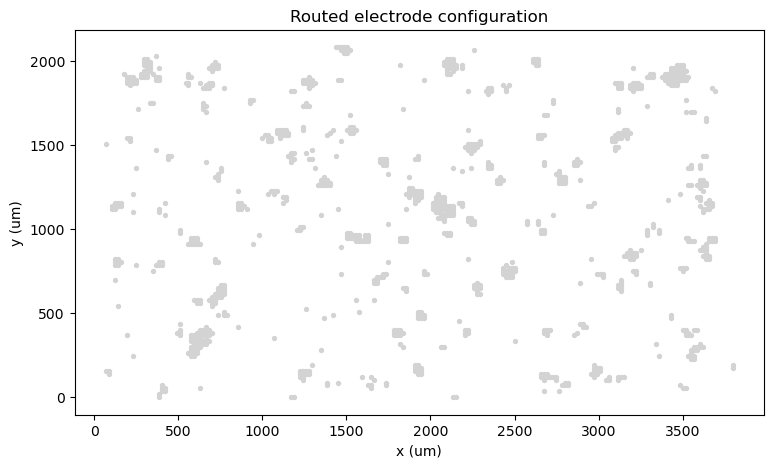

In [3]:
fig, ax = plt.subplots(figsize=(10, 5))
mea.plot_config_map(recording, ax=ax)
ax.set_title("Routed electrode configuration"); plt.show()


## 3. Online-detected spikes

### A first look at activity: rate and amplitude maps

During the recording, MaxLab flags spikes **live** (the *online-detected
events* described above). They are stored in the `.h5` next to the raw signal,
so we can see where the culture is active before doing any processing.

In [4]:
online = mea.load_online_spikes(row, data_root=DATA_ROOT)
duration_s = recording.get_num_frames() / recording.get_sampling_frequency()
print(f"{len(online):,} online spikes on {online['channel'].nunique()} channels")
online.head()

267,503 online spikes on 992 channels


,time,channel,amplitude_uv
0,0.00035,686,-33.536655
1,0.00095,366,-29.867571
2,0.00140,438,-28.739122
3,0.00465,1002,-33.120766
4,0.00465,902,-24.908590


For every electrode we compute the **spike rate** (spikes per second) and the
**median amplitude** of its spikes, and colour the electrode map by each.

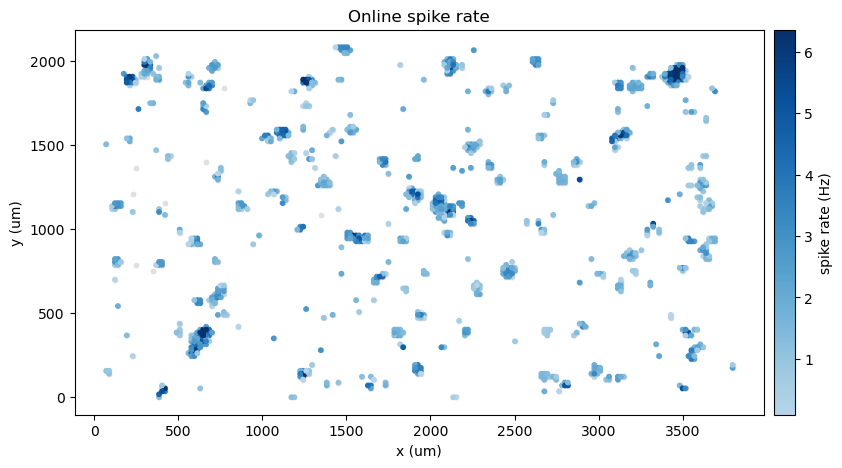

In [5]:
per_ch = online.groupby("channel").agg(n=("time", "size"),
                                      amplitude_uv=("amplitude_uv", "median"))
per_ch["rate_hz"] = per_ch["n"] / duration_s

fig, ax = plt.subplots(figsize=(10, 5))
mea.plot_activity_map(recording, per_ch["rate_hz"], channel_ids=per_ch.index,
                      ax=ax, cmap=mea.sequential_cmap(), s=10,
                      show_all=True, robust=True, label="spike rate (Hz)")
ax.set_title("Online spike rate"); plt.show()

The same electrodes, now coloured by the **median amplitude** of their spikes:

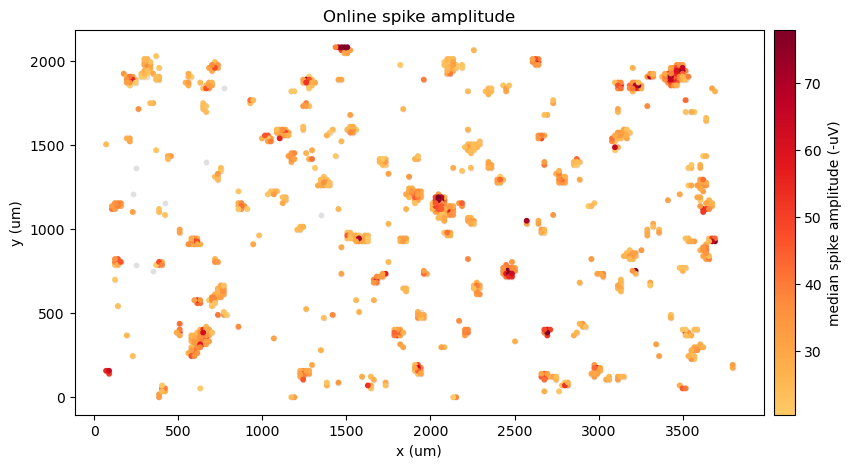

In [6]:
fig, ax = plt.subplots(figsize=(10, 5))
mea.plot_activity_map(recording, -per_ch["amplitude_uv"], channel_ids=per_ch.index,
                      ax=ax, cmap=mea.sequential_cmap("YlOrRd"), s=10,
                      show_all=True, robust=True,
                      label="median spike amplitude (-uV)")
ax.set_title("Online spike amplitude"); plt.show()

> Grey electrodes detected no spikes at all. The colour range covers the middle
> 96% of electrodes; the few extreme ones get the end colours.
>
> **💬 Discuss:** are the most active electrodes also the ones with the largest
> spikes?

### Watch the activity: a clip of the chip

The maps above sum up 2 minutes. Now **play** the first 10 seconds: each frame
is 50 ms, and every electrode is coloured by how many online spikes it detected
in that frame (grey = none). The trace below is the spike rate over the whole
chip; the black line marks the current frame. Use the buttons to play, pause,
step frame by frame, or change the speed.

In [7]:
mea.online_activity_clip(recording, online, t_start=0, duration=10)

> **💬 Discuss:** do the electrodes fire independently, or do many light up **together**?
> Step through one of the big peaks in the trace: where on the chip does it
> start, and how quickly does it spread? These synchronised events are
> **network bursts** — you will detect and measure them in Part 5.

## 4. Your turn

### Worked example — how big is one *second* of data?

Raw data is `n_channels x n_samples` numbers. One second = `fs` samples per
channel, and each number takes 2 bytes.

In [8]:
fs = recording.get_sampling_frequency()
n_channels = recording.get_num_channels()
bytes_per_second = n_channels * fs * 2
print(f"One second ~= {bytes_per_second/1e6:.1f} MB")

One second ~= 40.1 MB


### ✎ Your turn — how big is the *whole* recording (in GB)?

The recording lasts `duration` seconds. Multiply the per-second size by the
duration, then divide by `1e9` to get gigabytes.

In [9]:
duration = recording.get_num_frames() / fs

# TODO: replace the 0.0 with the size of the WHOLE recording in gigabytes.
#       (hint: bytes_per_second * duration, then / 1e9)
size_gb = 0.0

mea.check(size_gb, bytes_per_second * duration / 1e9,
          hint="size_gb = bytes_per_second * duration / 1e9")

[X] not quite yet.
   hint: size_gb = bytes_per_second * duration / 1e9
   you got: 0.0
   expected ~ 4.8120048


False

> This is why we never load the whole thing at once — we always slice.

### ✎ Your turn — how many spikes were detected online?

The `online` table has **one row per detected spike**, with its `time` (s),
`channel` and `amplitude_uv`. So:

- `len(online)` is the number of rows, i.e. the number of spikes;
- `online[online["time"] < t]` keeps only the rows (spikes) before time `t`.

**(a)** How many spikes were detected in the whole recording?

In [10]:
# TODO: replace the 0 with the number of rows of the `online` table.
n_spikes = 0

print(f"{n_spikes:,} spikes in {duration_s:.0f} s")
mea.check(n_spikes, len(online), hint="n_spikes = len(online)")

0 spikes in 120 s
[X] not quite yet.
   hint: n_spikes = len(online)
   you got: 0
   expected ~ 267503


False

**(b)** How many of them happened in the **first 10 seconds**?

In [11]:
# TODO: keep the spikes BEFORE 10 s: change the 0 into 10.
first_10s = online[online["time"] < 0]
n_first_10s = len(first_10s)

print(f"{n_first_10s:,} spikes in the first 10 s")
mea.check(n_first_10s, int((online["time"] < 10).sum()),
          hint='keep the rows with online["time"] < 10')

0 spikes in the first 10 s
[X] not quite yet.
   hint: keep the rows with online["time"] < 10
   you got: 0
   expected ~ 22639


False

> **💬 Discuss:** compare the two as **spikes per second**: `n_spikes / duration_s` and
> `n_first_10s / 10`. Is the first 10 s a fair sample of the whole recording?
> (Think about the network bursts you saw in the clip: how many fall into a
> 10 s window?)

**(c)** How many **electrodes** were active in the first 10 seconds, i.e. detected
at least one spike?

Each row of `first_10s` names its electrode in the `channel` column, and a busy
electrode appears in many rows. So count the **different** channels:
`first_10s["channel"].nunique()` (number of unique values).

In [12]:
# TODO: replace the 0 with the number of DIFFERENT channels in `first_10s`.
n_active = 0

print(f"{n_active} of {n_channels} recorded electrodes were active in the first 10 s")
mea.check(n_active, online.loc[online["time"] < 10, "channel"].nunique(),
          hint='n_active = first_10s["channel"].nunique()  (and check (b): time < 10)')

0 of 1002 recorded electrodes were active in the first 10 s
[X] not quite yet.
   hint: n_active = first_10s["channel"].nunique()  (and check (b): time < 10)
   you got: 0
   expected ~ 967


False

> **💬 Discuss:** why is `n_active` so much smaller than `n_first_10s`? What **fraction** of
> the electrodes was active: is the activity spread over the whole chip, or
> limited to a few spots? Compare with the rate map above.